***Cell 1: Install***

In [1]:
!pip install -q qiskit==1.2.4 qiskit-machine-learning==0.8.0 qiskit-algorithms==0.3.0 scikit-image opencv-python-headless

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 133.4/133.4 kB 3.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.8/4.8 MB 56.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 237.5/237.5 kB 10.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 308.6/308.6 kB 15.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 54.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.6/49.6 MB 18.1 MB/s eta 0:00:00


***Cell 2: Dataset***

In [2]:
from google.colab import drive, files
drive.mount('/content/drive')

!unzip -q "/content/drive/MyDrive/Plant Disease.zip" -d /content/PlantVillage
!ls /content/PlantVillage

Mounted at /content/drive
plantvillage  PlantVillage


***Cell 3: Imports, settings, features***

In [3]:
import os, cv2, time, json, joblib, hashlib, shutil
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from skimage.feature import hog
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.metrics import ConfusionMatrixDisplay

BASE = None
for root, dirs, _ in os.walk("/content/PlantVillage"):
    if any(d.lower().startswith(("potato", "tomato", "pepper")) for d in dirs):
        BASE = root; break
ALL_CLASSES = sorted(c for c in os.listdir(BASE)
                     if c.lower().startswith(("potato", "tomato", "pepper")))
CLASSES = [c for c in ALL_CLASSES if c.lower().startswith("potato")]   # Potato only
print("BASE:", BASE)
print("CLASSES (Potato):", CLASSES)

N = 100        # images per class (same as Classical)
Q_TRAIN = 120  # training images for ALL models (simulator is slow). Test stays the same 60 images.

def features(img):
    img = cv2.resize(img, (64, 64))
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    h = hog(gray, pixels_per_cell=(16, 16))
    hist = cv2.calcHist([img], [0, 1, 2], None, [4, 4, 4], [0, 256] * 3).flatten()
    return np.concatenate([h, hist])

BASE: /content/PlantVillage/PlantVillage
CLASSES (Potato): ['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']


***Cell 4: Explore***

Potato___Early_blight 1000
Potato___Late_blight 1000
Potato___healthy 152


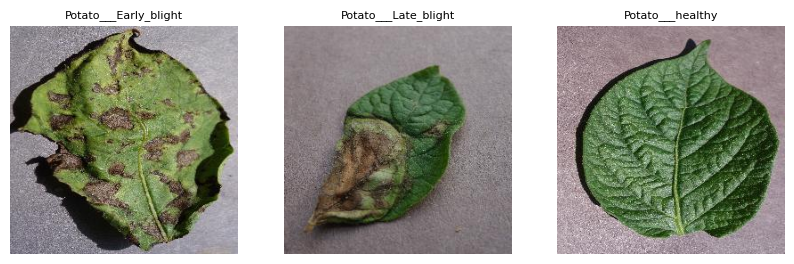

In [4]:
for c in CLASSES:
    print(c, len(os.listdir(os.path.join(BASE, c))))

fig, ax = plt.subplots(1, len(CLASSES), figsize=(10, 3))
for i, c in enumerate(CLASSES):
    f = sorted(os.listdir(os.path.join(BASE, c)))[0]
    img = cv2.imread(os.path.join(BASE, c, f))
    ax[i].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax[i].set_title(c, fontsize=8); ax[i].axis("off")
plt.show()

***Cell 5: Cleaning***

In [5]:
def clean_class(folder):
    seen, good = set(), []
    for f in sorted(os.listdir(folder)):
        p = os.path.join(folder, f)
        img = cv2.imread(p)
        if img is None: continue                     # corrupted image
        h = hashlib.md5(img.tobytes()).hexdigest()
        if h in seen: continue                       # duplicate image
        seen.add(h); good.append(p)
    return good

paths = {c: clean_class(os.path.join(BASE, c)) for c in CLASSES}
for c in CLASSES: print(c, "clean images:", len(paths[c]))

Potato___Early_blight clean images: 1000
Potato___Late_blight clean images: 1000
Potato___healthy clean images: 152


***Cell 6: Split and features***

In [6]:
all_p, all_y = [], []
for label, c in enumerate(CLASSES):
    sel = paths[c][:N]
    all_p += sel; all_y += [label] * len(sel)

# same split as Classical (random_state=42): same 60 test images
ptr, pte, ytr, yte = train_test_split(all_p, all_y, test_size=0.2,
                                      random_state=42, stratify=all_y)
# smaller training set for the quantum simulator (stratified)
ptr, _, ytr, _ = train_test_split(ptr, ytr, train_size=Q_TRAIN,
                                  random_state=42, stratify=ytr)

def extract(plist):
    return np.array([features(cv2.imread(p)) for p in plist])

Xtr = extract(ptr); y_tr = np.array(ytr)
Xte = extract(pte); y_te = np.array(yte)
print("Train:", Xtr.shape, "Test:", Xte.shape)

Train: (120, 388) Test: (60, 388)


***Cell 7: Scaling, PCA 4, scale to [0, π]***

In [7]:
scaler = StandardScaler().fit(Xtr)
pca = PCA(n_components=4).fit(scaler.transform(Xtr))
print("Variance kept:", pca.explained_variance_ratio_.sum())
Ztr = pca.transform(scaler.transform(Xtr))
mm = MinMaxScaler((0, np.pi)).fit(Ztr)
prep = lambda X: np.clip(mm.transform(pca.transform(scaler.transform(X))), 0, np.pi)
Xtr, Xte = prep(Xtr), prep(Xte)      # all models use these same 4 features

os.makedirs("out", exist_ok=True)
joblib.dump((scaler, pca, mm), "out/preprocess.pkl")
json.dump(CLASSES, open("out/classes.json", "w"))
np.savez("out/split.npz", Xtr=Xtr, Xte=Xte, ytr=y_tr, yte=y_te)

Variance kept: 0.3261136231072173


***Cell 8: Evaluation helper***

In [8]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import learning_curve
results = {}
def evaluate(name, model, kind, curve=None):
    t = time.time(); model.fit(Xtr, y_tr); tt = time.time() - t
    p = model.predict(Xte)
    results[name] = dict(type=kind, accuracy=accuracy_score(y_te, p),
        precision=precision_score(y_te, p, average="macro", zero_division=0),
        recall=recall_score(y_te, p, average="macro", zero_division=0),
        f1=f1_score(y_te, p, average="macro", zero_division=0),
        train_time_sec=tt, confusion=confusion_matrix(y_te, p).tolist(),
        curve=curve if curve is not None else [])
    print(name, {k: round(v, 3) for k, v in results[name].items() if isinstance(v, float)})
    return model
def add_lc(name, model):
    s, tr, va = learning_curve(model, Xtr, y_tr, cv=3, train_sizes=[0.4, 0.6, 0.8, 1.0], scoring="accuracy", shuffle=True, random_state=42)
    results[name]["learning"] = dict(sizes=s.tolist(), train=tr.mean(1).tolist(), val=va.mean(1).tolist())

***Cell 9: Classical models***

In [9]:
grids = {
  "SVM": (SVC(probability=True, random_state=42), {"C": [0.1, 1, 10], "kernel": ["rbf", "linear"]}),
  "RandomForest": (RandomForestClassifier(random_state=42),
                   {"n_estimators": [100, 200], "max_depth": [None, 5, 10]}),
  "MLP": (MLPClassifier(max_iter=1000, random_state=42),
          {"hidden_layer_sizes": [(32,), (32, 16)], "alpha": [0.0001, 0.01]}),
}
best = {}
for name, (m, g) in grids.items():
    gs = GridSearchCV(m, g, cv=5, scoring="f1_macro", n_jobs=-1).fit(Xtr, y_tr)
    best[name] = gs.best_estimator_
    print(name, gs.best_params_, "CV F1:", round(gs.best_score_, 3))

svm = evaluate("SVM", best["SVM"], "classical")
rf  = evaluate("Random Forest", best["RandomForest"], "classical")
mlp = evaluate("MLP", best["MLP"], "classical")
for n, m in [("SVM", svm), ("Random Forest", rf), ("MLP", mlp)]:
    add_lc(n, m)

SVM {'C': 1, 'kernel': 'linear'} CV F1: 0.653
RandomForest {'max_depth': 5, 'n_estimators': 100} CV F1: 0.604


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


MLP {'alpha': 0.0001, 'hidden_layer_sizes': (32,)} CV F1: 0.644
SVM {'accuracy': 0.633, 'precision': 0.634, 'recall': 0.633, 'f1': 0.623, 'train_time_sec': 0.004}
Random Forest {'accuracy': 0.567, 'precision': 0.566, 'recall': 0.567, 'f1': 0.566, 'train_time_sec': 0.107}


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


MLP {'accuracy': 0.567, 'precision': 0.567, 'recall': 0.567, 'f1': 0.565, 'train_time_sec': 0.302}


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perce

***Cell 10: QSVM (Quantum Support Vector Machine)***

In [10]:
from qiskit.circuit.library import ZZFeatureMap, RealAmplitudes
from qiskit_machine_learning.algorithms import QSVC, VQC, NeuralNetworkClassifier
from qiskit_machine_learning.kernels import FidelityQuantumKernel
from qiskit_algorithms.optimizers import COBYLA
qsvm = evaluate("QSVM", QSVC(quantum_kernel=FidelityQuantumKernel(
        feature_map=ZZFeatureMap(4, reps=2, entanglement="linear"))), "quantum")

QSVM {'accuracy': 0.4, 'precision': 0.374, 'recall': 0.4, 'f1': 0.375, 'train_time_sec': 24.721}


***Cell 11: VQC (Variational Quantum Classifier)***

In [11]:
loss_vqc = []
vqc = VQC(feature_map=ZZFeatureMap(4, reps=1), ansatz=RealAmplitudes(4, reps=3),
          optimizer=COBYLA(maxiter=100), callback=lambda w, f: loss_vqc.append(float(f)))
evaluate("VQC", vqc, "quantum", curve=loss_vqc)

VQC {'accuracy': 0.4, 'precision': 0.394, 'recall': 0.4, 'f1': 0.395, 'train_time_sec': 36.476}


***Cell 12: QNN (Quantum Neural Network)***

In [12]:
from qiskit import QuantumCircuit
from qiskit_machine_learning.neural_networks import SamplerQNN
fm = ZZFeatureMap(4, reps=1); an = RealAmplitudes(4, reps=3)
qc = QuantumCircuit(4); qc.compose(fm, inplace=True); qc.compose(an, inplace=True)
qnn = SamplerQNN(circuit=qc, input_params=fm.parameters, weight_params=an.parameters,
                 interpret=lambda x: x % 3, output_shape=3)
loss_qnn = []
core = NeuralNetworkClassifier(qnn, loss="cross_entropy", one_hot=True,
        optimizer=COBYLA(maxiter=100), callback=lambda w, f: loss_qnn.append(float(f)))
class QNNClf:
    def __init__(s, c): s.c = c
    def fit(s, X, y): s.c.fit(X, np.eye(3)[y]); return s
    def predict(s, X): return np.argmax(s.c.predict(X), axis=1)
qnn_model = evaluate("QNN", QNNClf(core), "quantum", curve=loss_qnn)

/tmp/ipykernel_2725/1610086854.py:5: DeprecationWarning: V1 Primitives are deprecated as of qiskit-machine-learning 0.8.0 and will be removed no sooner than 4 months after the release date. Use V2 primitives for continued compatibility and support.
  qnn = SamplerQNN(circuit=qc, input_params=fm.parameters, weight_params=an.parameters,


QNN {'accuracy': 0.383, 'precision': 0.367, 'recall': 0.383, 'f1': 0.368, 'train_time_sec': 36.595}


***Cell 13: Results table, graphs, save***

,type,accuracy,precision,recall,f1,train_time_sec
SVM,classical,0.633,0.634,0.633,0.623,0.004
Random Forest,classical,0.567,0.566,0.567,0.566,0.107
MLP,classical,0.567,0.567,0.567,0.565,0.302
QSVM,quantum,0.400,0.374,0.400,0.375,24.721
VQC,quantum,0.400,0.394,0.400,0.395,36.476
QNN,quantum,0.383,0.367,0.383,0.368,36.595


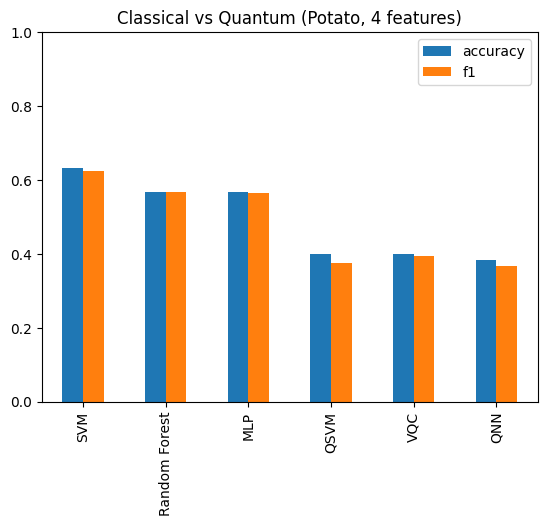

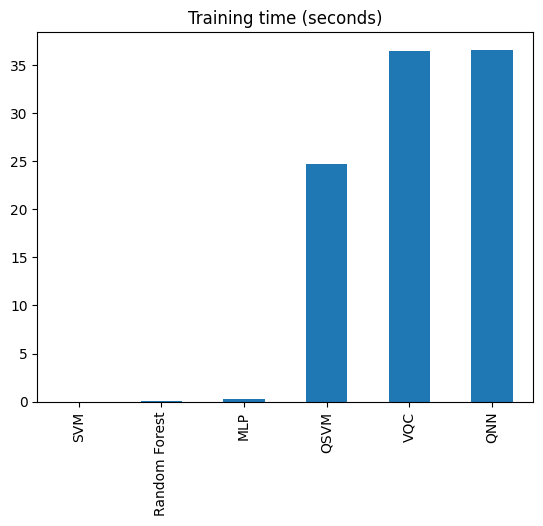

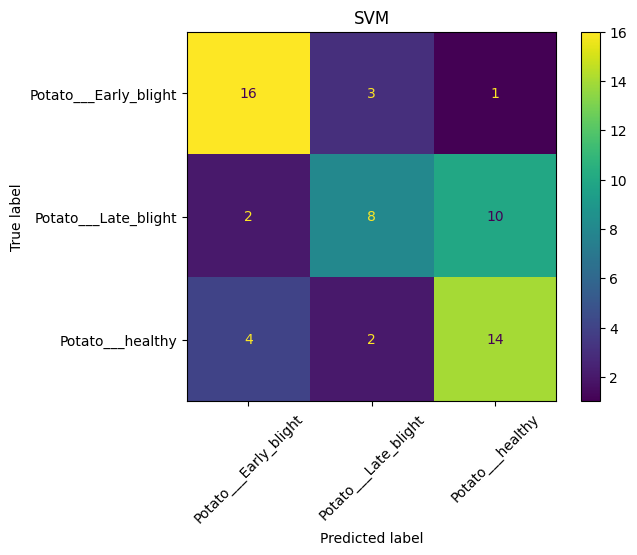

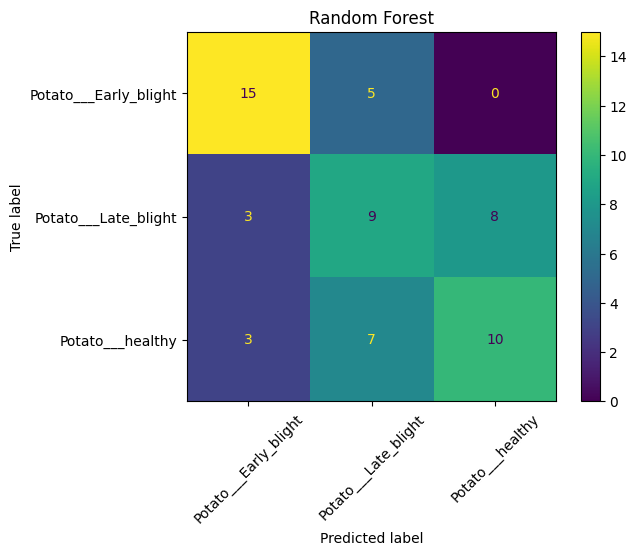

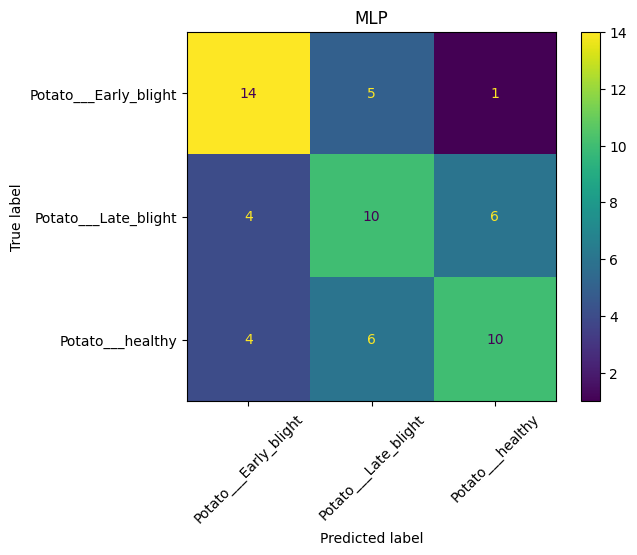

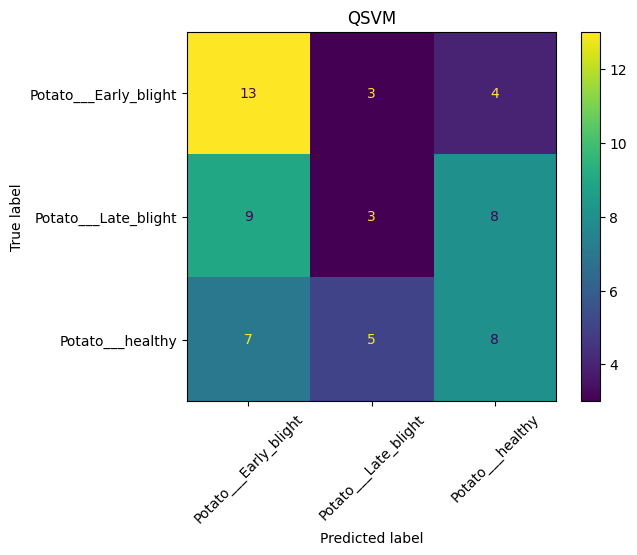

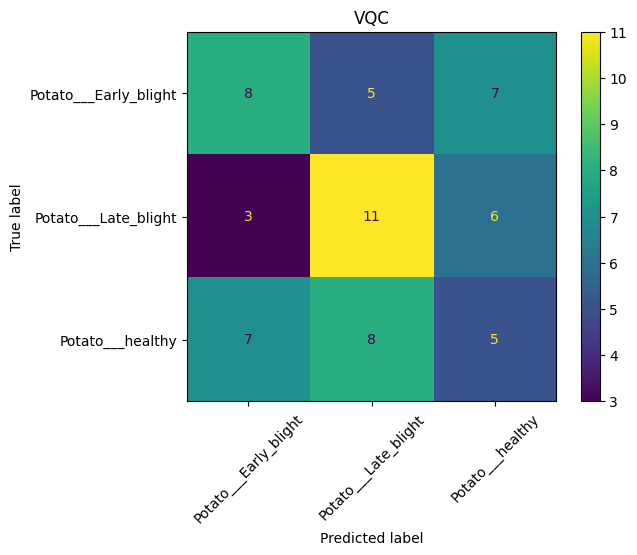

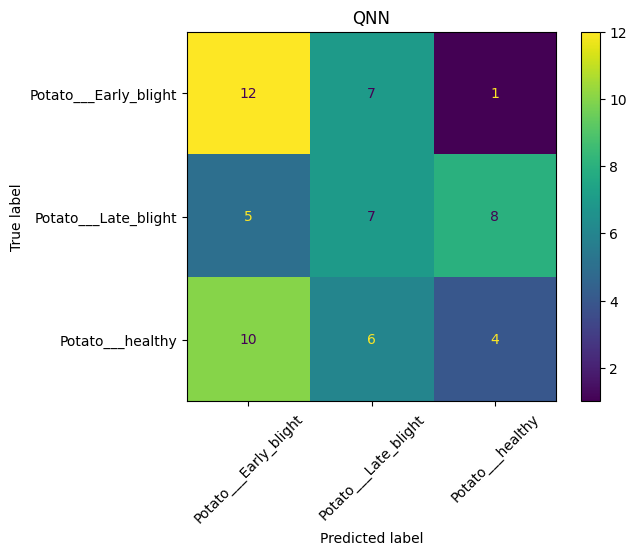

In [13]:
df = pd.DataFrame(results).T[["type", "accuracy", "precision", "recall", "f1", "train_time_sec"]]
cols = ["accuracy", "precision", "recall", "f1", "train_time_sec"]
df[cols] = df[cols].astype(float).round(3)
display(df)
df.to_csv("out/comparison_results.csv")
json.dump(results, open("out/model_results.json", "w"))
for n, m in [("svm", svm), ("rf", rf), ("mlp", mlp)]:
    joblib.dump(m, f"out/{n}.pkl")
for n, m in [("qsvm", qsvm), ("vqc", vqc), ("qnn", core)]:
    try: m.save(f"out/{n}.model")
    except Exception as e: print("save failed", n, e)

df[["accuracy", "f1"]].plot(kind="bar", ylim=(0, 1), title="Classical vs Quantum (Potato, 4 features)")
plt.show()
df["train_time_sec"].plot(kind="bar", title="Training time (seconds)")
plt.show()
for n, r in results.items():
    ConfusionMatrixDisplay(np.array(r["confusion"]), display_labels=CLASSES).plot(xticks_rotation=45)
    plt.title(n); plt.show()

***Cell 14: Samples and download***

In [14]:
os.makedirs("out/samples", exist_ok=True)
for k, c in enumerate(CLASSES):
    for i, p in enumerate(paths[c][:3]):
        shutil.copy(p, f"out/samples/{c}_{i+1}.jpg")

!zip -qr quantum_outputs.zip out
files.download("quantum_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

***Cell 15: Predict one image with all 6 models***

In [16]:
def _pred(m, x):
    p = np.asarray(m.predict(x))
    return int(np.argmax(p)) if p.size > 1 else int(p.ravel()[0])

def predict_image(path):
    x = prep(np.array([features(cv2.imread(path))]))
    models = {"SVM": svm, "Random Forest": rf, "MLP": mlp,
              "QSVM": qsvm, "VQC": vqc, "QNN": qnn_model}
    return {n: CLASSES[_pred(m, x)] for n, m in models.items()}

print(predict_image(pte[0]), "| true:", CLASSES[y_te[0]])

{'SVM': 'Potato___Early_blight', 'Random Forest': 'Potato___Early_blight', 'MLP': 'Potato___Early_blight', 'QSVM': 'Potato___Early_blight', 'VQC': 'Potato___Late_blight', 'QNN': 'Potato___Early_blight'} | true: Potato___Early_blight
